# Native Sparse Attention, part 4: gating and the full layer
*Companion notebooks to Yuan et al., 2025, [Native Sparse Attention](https://arxiv.org/abs/2502.11089). Part 4 of 7. Parts 1-3 built the three branches; here we combine them and train the result.*

**TL;DR.** NSA's output for a query is a **gated sum** of three attention results: `o = g_cmp * o_cmp + g_slc * o_slc + g_win * o_win`, where each gate is a number in [0, 1] produced from the token itself by a small network with a sigmoid (the paper's equation 5). We assemble the layer, verify it is causal and reads far fewer tokens than full attention, then train it on a toy retrieval task next to a full-attention layer of the same width. **Measured at toy scale (our numbers, not the paper's):** NSA learns the task but more slowly than full attention (final error below, in the results table), and when we switch branches off after training, the selection branch turns out to carry the long-range lookup (switching it off sends the error back to the 'not learned' level), while the window and compressed branches matter far less in this toy. At the paper's scale (27B parameters, 260B tokens) Yuan et al. report NSA matching or beating full attention; we make no such claim for our toy.

<img src="nsa_assets/fig4_loss.png" width="560"/>

*Figure 4 of the paper: pretraining loss of a 27B model, full attention vs NSA. Notice both curves are smooth and NSA sits slightly lower; our toy training curves below behave differently, and we say how.*

In [1]:
import math, time
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(0); np.random.seed(0)
DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"   # used only where a notebook trains
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
CMP_C, SLC_C, WIN_C, FULL_C = "#1c7ed6", "#d9480f", "#2f9e44", "#495057"      # one colour per branch, used in every notebook
NEG = -1e30                                                                     # a finite "minus infinity": a fully masked row gives uniform weights, never NaN

CHECKS = []
def check(name, ok, detail=""):
    """Record + print PASS/FAIL. Every claim in these notebooks is backed by one of these lines."""
    CHECKS.append((name, bool(ok)))
    print(("PASS  " if ok else "FAIL  ") + name + (f"   [{detail}]" if detail else ""))

In [2]:
def full_causal_attention(q, k, v):
    """Ordinary causal attention, with the grouped-query layout NSA uses.
    q: (B, G, H, T, dk)   G key/value groups, H query heads share each group's K and V (GQA)
    k: (B, G, T, dk)      v: (B, G, T, dv)       returns (output (B,G,H,T,dv), weights (B,G,H,T,T))"""
    T, dk = q.shape[-2], q.shape[-1]
    scores = torch.einsum("bghtd,bgsd->bghts", q, k) / math.sqrt(dk)          # how much query t likes key s
    causal = torch.ones(T, T, dtype=torch.bool, device=q.device).tril()        # token t may only look at tokens <= t
    p = scores.masked_fill(~causal, NEG).softmax(-1)                           # each row sums to 1
    return torch.einsum("bghts,bgsd->bghtd", p, v), p

In [3]:
class Compressor(nn.Module):
    """Squeeze every block of `l` consecutive keys (or values) into ONE vector.
    Blocks start every `d` tokens; d < l means neighbouring blocks overlap (paper: l=32, d=16).
    phi = learnable position embedding inside the block -> flatten -> small MLP."""
    def __init__(self, dim, l, d):
        super().__init__(); self.l, self.d = l, d
        self.pos = nn.Parameter(torch.zeros(l, dim))                           # intra-block position encoding
        self.mlp = nn.Sequential(nn.Linear(l * dim, dim), nn.GELU(), nn.Linear(dim, dim))
        nn.init.zeros_(self.mlp[2].weight); nn.init.zeros_(self.mlp[2].bias)   # our choice: start as plain mean-pooling, learn a correction
    def forward(self, x):                                                      # x: (B, G, T, dim)
        blocks = x.unfold(2, self.l, self.d).transpose(-1, -2)                 # (B, G, Nc, l, dim): the overlapping blocks
        return blocks.mean(-2) + self.mlp((blocks + self.pos).flatten(-2))     # (B, G, Nc, dim)   mean-pool + learned phi

def n_compressed(T, l, d): return (T - l) // d + 1

def compressed_valid(T, l, d, device="cpu"):
    """(T, Nc) bool. Compressed block j covers tokens [j*d, j*d + l). Query t may use it only if ALL of its
    tokens are <= t (otherwise the block would leak the future)."""
    j = torch.arange(n_compressed(T, l, d), device=device); t = torch.arange(T, device=device)
    return (j[None, :] * d + l - 1) <= t[:, None]

def compressed_attention(q, k_cmp, v_cmp, valid):
    """q (B,G,H,T,dk) attends to the compressed keys. Returns (output, attention weights p_cmp (B,G,H,T,Nc))."""
    s = torch.einsum("bghtd,bgcd->bghtc", q, k_cmp) / math.sqrt(q.shape[-1])
    p = s.masked_fill(~valid, NEG).softmax(-1) * valid                          # zero out invalid blocks (and empty rows)
    return torch.einsum("bghtc,bgcd->bghtd", p, v_cmp), p

In [4]:
def overlap_matrix(T, l, d, lp, device="cpu"):
    """M[i, j] = number of tokens shared by compressed block i and selection block j (size lp).
    p_slc = p_cmp @ M turns 'which compressed blocks does the query like' into 'which selection blocks look important'."""
    Nc, Ns = n_compressed(T, l, d), T // lp
    M = torch.zeros(Nc, Ns)
    for i in range(Nc):
        a, b = i * d, i * d + l
        for j in range(Ns): M[i, j] = max(0, min(b, (j + 1) * lp) - max(a, j * lp))
    return (M / d).to(device)

def minmax_block_scores(q, k, lp):
    """Quest-style heuristic (NO learned parameters): upper-bound each block's best dot product from per-channel min/max of its keys."""
    B, G, T, dk = k.shape; kb = k.view(B, G, T // lp, lp, dk)
    kmin, kmax = kb.min(3).values, kb.max(3).values                             # (B,G,Ns,dk)
    qq = q.unsqueeze(-2)                                                       # (B,G,H,T,1,dk)
    return torch.maximum(qq * kmin[:, :, None, None], qq * kmax[:, :, None, None]).sum(-1)   # (B,G,H,T,Ns)

def select_blocks(block_score, T, lp, n, n_local=2):
    """block_score (B,G,H,T,Ns) -> indices (B,G,T,n) of the blocks each query will read at full resolution.
    1) add scores over the heads of a group (they must agree because they share one KV cache)  [paper eq. 10]
    2) only blocks that start at or before the query are allowed
    3) the first block and the query's own / previous block are always kept (paper: 1 initial + 2 local)
    4) take the top-n"""
    s = block_score.sum(2)                                                      # (B,G,T,Ns)
    Ns = s.shape[-1]; j = torch.arange(Ns, device=s.device); t = torch.arange(T, device=s.device); tb = t // lp
    valid = j[None, :] * lp <= t[:, None]
    forced = ((j[None, :] == 0) | (j[None, :] == tb[:, None]) | ((j[None, :] == tb[:, None] - 1) & (n_local >= 2))) & valid
    s = torch.where(forced, torch.full_like(s, 1e9), s.masked_fill(~valid, NEG))
    return s.topk(n, dim=-1).indices

def selected_attention(q, k, v, idx, lp):
    """Gather the chosen blocks of K,V for every query and attend to them. Cost per query = n*lp tokens."""
    B, G, T, dk = k.shape; Ns = T // lp; n = idx.shape[-1]
    kb, vb = k.view(B, G, Ns, lp, dk), v.view(B, G, Ns, lp, v.shape[-1])
    bi, gi = torch.arange(B, device=k.device)[:, None, None, None], torch.arange(G, device=k.device)[None, :, None, None]
    ks, vs = kb[bi, gi, idx].reshape(B, G, T, n * lp, dk), vb[bi, gi, idx].reshape(B, G, T, n * lp, -1)   # (B,G,T,n*lp,.)
    pos = (idx[..., None] * lp + torch.arange(lp, device=k.device)).reshape(B, G, T, n * lp)             # real position of every gathered token
    valid = (pos <= torch.arange(T, device=k.device)[None, None, :, None])[:, :, None]                    # (B,G,1,T,n*lp) causal
    s = torch.einsum("bghtd,bgtsd->bghts", q, ks) / math.sqrt(dk)
    p = s.masked_fill(~valid, NEG).softmax(-1) * valid
    return torch.einsum("bghts,bgtsd->bghtd", p, vs)

In [5]:
def window_attention(q, k, v, w):
    """Attend only to the last w tokens (including the current one)."""
    B, G, T, dk = k.shape
    kw = F.pad(k, (0, 0, w - 1, 0)).unfold(2, w, 1).transpose(-1, -2)          # (B,G,T,w,dk): window of every position
    vw = F.pad(v, (0, 0, w - 1, 0)).unfold(2, w, 1).transpose(-1, -2)
    pos = torch.arange(T, device=k.device)[:, None] - (w - 1) + torch.arange(w, device=k.device)[None, :]
    valid = (pos >= 0)[None, None, None]                                         # the left padding is not a real token
    s = torch.einsum("bghtd,bgtwd->bghtw", q, kw) / math.sqrt(dk)
    p = s.masked_fill(~valid, NEG).softmax(-1) * valid
    return torch.einsum("bghtw,bgtwd->bghtd", p, vw)

## Gates: how much to trust each branch

Each branch returns a vector for the query. The layer must decide how to mix them, and the right mix depends on the token: a token in the middle of a name needs the window, a token asking a question about a distant fact needs selection. The paper computes, per query and per head, three gate values `g_c` from the input features through an MLP and a sigmoid; the sigmoid keeps each in [0, 1] and, unlike a softmax, lets the branches be on together.

A tiny example with numbers: three branch outputs for one head, two numbers each.

In [6]:
o_cmp, o_slc, o_win = torch.tensor([1.0, 0.0]), torch.tensor([0.0, 1.0]), torch.tensor([2.0, 2.0])
for name, g in {"all gates 1/3": (1/3, 1/3, 1/3), "trusts selection": (0.1, 0.9, 0.1), "trusts window": (0.0, 0.1, 1.0)}.items():
    o = g[0] * o_cmp + g[1] * o_slc + g[2] * o_win
    print(f"{name:18s} gates {tuple(round(x, 2) for x in g)} -> output {o.numpy().round(2)}")
check("a gated sum with gates (0.1, 0.9, 0.1) is dominated by the selection branch", torch.allclose(0.1 * o_cmp + 0.9 * o_slc + 0.1 * o_win, torch.tensor([0.3, 1.1]), atol=1e-6))

all gates 1/3      gates (0.33, 0.33, 0.33) -> output [1. 1.]
trusts selection   gates (0.1, 0.9, 0.1) -> output [0.3 1.1]
trusts window      gates (0.0, 0.1, 1.0) -> output [2.  2.1]
PASS  a gated sum with gates (0.1, 0.9, 0.1) is dominated by the selection branch


## The full layer

`NSALayer` below is the whole mechanism in one class. Read `forward` in order: project to queries; give each branch **its own** keys and values (part 3); compress keys and values and attend to them (part 1); reuse the compressed attention weights to pick blocks (part 2); attend to the picked blocks; attend to the window (part 3); gate and sum; project out. Two options exist only for the experiments in part 6 (`select` chooses how blocks are scored, `shared_kv` removes the independent keys/values); a `FullLayer` with the same interface is the baseline.

In [7]:
class NSALayer(nn.Module):
    """Native Sparse Attention for one layer: three branches (compressed, selected, sliding window), each with its OWN
    keys/values, mixed by learned sigmoid gates.   o_t = sum_c g_c * Attn(q_t, K_c, V_c)     [paper eq. 5]
    Options exist only for the ablations in notebooks 4 and 6 (shared_kv, select mode, gate mode)."""
    def __init__(self, d_model, G=1, H=4, dk=32, l=8, d=4, lp=8, n=6, w=16, T=128,
                 shared_kv=False, select="cmp", gate="learned"):
        super().__init__(); self.G, self.H, self.dk, self.l, self.d, self.lp, self.n, self.w = G, H, dk, l, d, lp, n, w
        self.shared_kv, self.select, self.gate_mode = shared_kv, select, gate
        self.q = nn.Linear(d_model, G * H * dk)
        names = ["c"] if shared_kv else ["c", "s", "w"]
        self.k = nn.ModuleDict({c: nn.Linear(d_model, G * dk) for c in names}); self.v = nn.ModuleDict({c: nn.Linear(d_model, G * dk) for c in names})
        self.comp_k, self.comp_v = Compressor(dk, l, d), Compressor(dk, l, d)
        self.gate = nn.Linear(d_model, G * H * 3); self.out = nn.Linear(G * H * dk, d_model)
        self.register_buffer("M", overlap_matrix(T, l, d, lp), persistent=False)
        self.register_buffer("valid_c", compressed_valid(T, l, d), persistent=False)
    def forward(self, x, return_aux=False):                                      # x: (B, T, d_model)
        B, T, _ = x.shape; G, H, dk = self.G, self.H, self.dk
        q = self.q(x).view(B, T, G, H, dk).permute(0, 2, 3, 1, 4)                # (B,G,H,T,dk)
        kv = lambda c: (self.k["c" if self.shared_kv else c](x).view(B, T, G, dk).transpose(1, 2),
                        self.v["c" if self.shared_kv else c](x).view(B, T, G, dk).transpose(1, 2))
        (kc, vc), (ks, vs), (kw, vw) = kv("c"), kv("s"), kv("w")
        o_cmp, p_cmp = compressed_attention(q, self.comp_k(kc), self.comp_v(vc), self.valid_c[:T])
        if self.select == "cmp":       score = p_cmp @ self.M                                         # free: reuse the compression attention
        elif self.select == "minmax":  score = minmax_block_scores(q, ks, self.lp)                    # Quest-style heuristic
        else:                          score = torch.rand(B, G, H, T, T // self.lp, device=x.device)  # random control
        idx = select_blocks(score, T, self.lp, self.n)
        o_slc = selected_attention(q, ks, vs, idx, self.lp)
        o_win = window_attention(q, kw, vw, self.w)
        g = torch.sigmoid(self.gate(x)).view(B, T, G, H, 3).permute(0, 2, 3, 1, 4) if self.gate_mode == "learned" else torch.ones(B, G, H, T, 3, device=x.device) / 3
        o = g[..., 0:1] * o_cmp + g[..., 1:2] * o_slc + g[..., 2:3] * o_win                       # gated sum of the 3 branches
        y = self.out(o.permute(0, 3, 1, 2, 4).reshape(B, T, G * H * dk))
        return (y, dict(p_cmp=p_cmp, idx=idx, gate=g, o=(o_cmp, o_slc, o_win))) if return_aux else y

class FullLayer(nn.Module):
    """Same interface and same projection sizes, but ordinary full causal attention (the baseline)."""
    def __init__(self, d_model, G=1, H=4, dk=32, **_):
        super().__init__(); self.G, self.H, self.dk = G, H, dk
        self.q, self.k, self.v = nn.Linear(d_model, G * H * dk), nn.Linear(d_model, G * dk), nn.Linear(d_model, G * dk)
        self.out = nn.Linear(G * H * dk, d_model)
    def forward(self, x, return_aux=False):
        B, T, _ = x.shape; G, H, dk = self.G, self.H, self.dk
        q = self.q(x).view(B, T, G, H, dk).permute(0, 2, 3, 1, 4)
        o, p = full_causal_attention(q, self.k(x).view(B, T, G, dk).transpose(1, 2), self.v(x).view(B, T, G, dk).transpose(1, 2))
        y = self.out(o.permute(0, 3, 1, 2, 4).reshape(B, T, G * H * dk))
        return (y, dict(p=p)) if return_aux else y

In [8]:
torch.manual_seed(0)
B, T = 2, 128
nsa = NSALayer(64, T=T).eval(); x = torch.randn(B, T, 64)
y, aux = nsa(x, return_aux=True)
print("input", tuple(x.shape), "-> output", tuple(y.shape), "| compressed weights", tuple(aux["p_cmp"].shape), "| chosen blocks", tuple(aux["idx"].shape), "| gates", tuple(aux["gate"].shape))
check("the layer keeps the shape (batch, T, d_model)", y.shape == x.shape)
check("gates are in (0, 1)", bool((aux["gate"] > 0).all() and (aux["gate"] < 1).all()))

x2 = x.clone(); x2[:, 90:] = torch.randn_like(x2[:, 90:]); y2 = nsa(x2)
check("causality: scrambling positions 90+ changes nothing before 90 (all three branches together)", (y[:, :90] - y2[:, :90]).abs().max() < 1e-5)
check("...and the test has teeth: later positions DO change", (y[:, 90:] - y2[:, 90:]).abs().max() > 1e-3)

t_late = torch.arange(T - 16, T)
read = nsa.valid_c[t_late].sum(1) + nsa.n * nsa.lp + nsa.w                       # compressed (visible) + selected + window
print(f"late positions read {read.float().mean():.0f} tokens each vs {(t_late + 1).float().mean():.0f} for full attention ({100 * read.float().mean() / (t_late + 1).float().mean():.0f}%)")

input (2, 128, 64) -> output (2, 128, 64) | compressed weights (2, 1, 4, 128, 31) | chosen blocks (2, 1, 128, 6) | gates (2, 1, 4, 128, 3)
PASS  the layer keeps the shape (batch, T, d_model)
PASS  gates are in (0, 1)
PASS  causality: scrambling positions 90+ changes nothing before 90 (all three branches together)
PASS  ...and the test has teeth: later positions DO change
late positions read 93 tokens each vs 120 for full attention (77%)


**An honest note on sparsity at toy scale.** At 128 tokens this configuration (compression blocks of 8 every 4, 6 selected blocks of 8, window 16) reads roughly four fifths of the tokens a full-attention query would. That is barely sparse. We kept it because sparser configurations we tried (fewer selected blocks, longer compression blocks) did not learn the retrieval task in our training budget at all, and a layer that has not learned anything cannot teach us about the mechanism. So the experiments below test whether the *mechanism* learns and how the branches divide the work, **not** whether NSA saves compute; part 5 covers the compute argument at the paper's scale.

## A task that needs all three branches

We need a task where selection has to find something specific and far away, and where there is also an easy local signal (the situation the window branch is designed for). Our toy, "address retrieval": every position holds a random content vector `c_t` and a random id `e_t`. The last 16 positions are each handed the id of **one far-away earlier position** (more than 16 tokens back) and must output **that position's content plus the mean content of their own last 16 tokens**:

&nbsp;&nbsp;&nbsp;&nbsp;`target_t = c_pi(t) + mean(c_{t-15..t})`

The second term is local and easy. The first needs a precise long-range lookup. Predicting only the local term leaves an error of exactly 1.0 per output number (the variance of `c`), so **an error near 1.0 means retrieval was not learned; near 0 means it was.**

In [9]:
def fourier(T, dim=8):
    t = torch.arange(T)[:, None].float(); f = 2 ** torch.arange(dim // 2)[None].float()
    return torch.cat([torch.sin(t * f * 0.02), torch.cos(t * f * 0.02)], -1)

def make_retrieval_batch(B, T=128, n_q=16, w=16, dc=16, de=64, gen=None):
    """'Address retrieval' toy: every position holds a content vector c_t and a random id e_t. Each of the last n_q
    positions is given the id of ONE far-away earlier position and must output that position's content
    PLUS the mean content of its own recent window.   target_t = c_{pi(t)} + mean(c_{t-w+1..t}).
    The window part is local and easy; the first part needs a precise long-range lookup."""
    c = torch.randn(B, T, dc, generator=gen); e = torch.randn(B, T, de, generator=gen)
    pi = torch.randint(0, T - n_q - w, (B, n_q), generator=gen)                 # far from every query (> w away)
    a = torch.zeros(B, T, de); a[:, T - n_q:] = torch.gather(e, 1, pi[..., None].expand(B, n_q, de))
    local = torch.stack([c[:, max(0, t - w + 1): t + 1].mean(1) for t in range(T - n_q, T)], 1)   # (B, n_q, dc)
    far = torch.gather(c, 1, pi[..., None].expand(B, n_q, dc))
    x = torch.cat([c, e, a, fourier(T).expand(B, T, 8)], -1)
    return x, far + local, far, local

class ToyModel(nn.Module):
    def __init__(self, layer_fn, d_in=16 + 64 + 64 + 8, d_model=64, dc=16):
        super().__init__(); self.inp, self.layer, self.out = nn.Linear(d_in, d_model), layer_fn(d_model), nn.Linear(d_model, dc)
    def forward(self, x, n_q=16):
        h = self.inp(x); h = h + self.layer(h); return self.out(h[:, -n_q:])

def train_toy(model, steps=600, bs=16, lr=3e-3, seed=0, T=128, log_every=100, verbose=True):
    g = torch.Generator().manual_seed(seed); model.to(DEVICE).train()
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.0); warm = max(1, steps // 20)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1, (s + 1) / warm) * 0.5 * (1 + math.cos(math.pi * s / steps)))
    hist, t0 = [], time.time()
    for s in range(steps):
        x, y, _, _ = make_retrieval_batch(bs, T=T, gen=g)
        loss = F.mse_loss(model(x.to(DEVICE)), y.to(DEVICE)); opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step(); hist.append(loss.item())
        if verbose and (s + 1) % log_every == 0: print(f"  step {s+1:5d}  loss {np.mean(hist[-log_every:]):.4f}  ({time.time()-t0:.0f}s)")
    model.cpu()
    return hist

@torch.no_grad()
def eval_toy(model, n=64, seed=999, T=128):
    """Mean squared error per output number. 1.0 = 'solved the local part, ignored retrieval'; 0 = perfect."""
    model.eval().to(DEVICE); g = torch.Generator().manual_seed(seed); x, y, far, local = make_retrieval_batch(n, T=T, gen=g)
    pred = model(x.to(DEVICE)).cpu(); model.train().cpu()
    return F.mse_loss(pred, y).item()

In [10]:
x, y, far, local = make_retrieval_batch(4, gen=torch.Generator().manual_seed(0))
print("input", tuple(x.shape), " target", tuple(y.shape), "(only the last 16 positions are scored)")
check("target = far content + local mean", torch.allclose(y, far + local))
check("predicting only the local part leaves error ~1.0 per number (the 'retrieval not learned' level)", abs(F.mse_loss(local, y).item() - 1.0) < 0.15, f"{F.mse_loss(local, y).item():.2f}")

input (4, 128, 152)  target (4, 16, 16) (only the last 16 positions are scored)
PASS  target = far content + local mean
PASS  predicting only the local part leaves error ~1.0 per number (the 'retrieval not learned' level)   [1.01]


## Training: NSA next to full attention

Same input projection, same width (64), same output head, same optimiser (AdamW, learning rate 3e-3 with warm-up and cosine decay), same data stream. Only the attention layer differs. Full attention trains for 1,500 steps and NSA for 3,000, because in our pilot runs NSA needed longer (an earlier pilot with a randomly initialised compressor was still near 0.8 at 1,500 steps; we have not re-measured the final configuration at 1,500 steps). We report both so the step difference is visible and not hidden.

  step   500  loss 0.7659  (20s)


  step  1000  loss 0.1116  (37s)


  step  1500  loss 0.0945  (55s)
full attention trained in 60s


  step  1000  loss 0.8686  (76s)


  step  2000  loss 0.4197  (146s)


  step  3000  loss 0.3732  (214s)
NSA trained in 214s



held-out error per output number (1.0 = retrieval not learned, 0 = perfect):   full attention 0.086   NSA 0.346


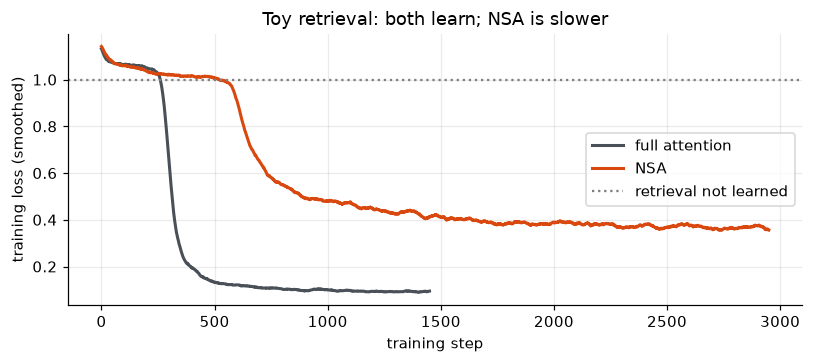

PASS  full attention learns the retrieval part (error < 0.5)   [0.086]
PASS  NSA also learns it (error clearly below the 1.0 'not learned' level)   [0.346]


In [11]:
STEPS_FULL, STEPS_NSA = 1500, 3000
torch.manual_seed(0); full_m = ToyModel(lambda dm: FullLayer(dm))
t0 = time.time(); h_full = train_toy(full_m, steps=STEPS_FULL, log_every=500); print(f"full attention trained in {time.time() - t0:.0f}s")
torch.manual_seed(0); nsa_m = ToyModel(lambda dm: NSALayer(dm))
t0 = time.time(); h_nsa = train_toy(nsa_m, steps=STEPS_NSA, log_every=1000); print(f"NSA trained in {time.time() - t0:.0f}s")
mse_full, mse_nsa = eval_toy(full_m), eval_toy(nsa_m)
print(f"\nheld-out error per output number (1.0 = retrieval not learned, 0 = perfect):   full attention {mse_full:.3f}   NSA {mse_nsa:.3f}")
sm = lambda h, w=50: np.convolve(h, np.ones(w) / w, "valid")
fig, ax = plt.subplots(figsize=(7.5, 3.4)); ax.plot(sm(h_full), color=FULL_C, lw=2, label="full attention"); ax.plot(sm(h_nsa), color=SLC_C, lw=2, label="NSA")
ax.axhline(1.0, color="gray", ls=":", label="retrieval not learned"); ax.set_xlabel("training step"); ax.set_ylabel("training loss (smoothed)"); ax.set_title("Toy retrieval: both learn; NSA is slower"); ax.legend(); plt.tight_layout(); plt.show()
check("full attention learns the retrieval part (error < 0.5)", mse_full < 0.5, f"{mse_full:.3f}")
check("NSA also learns it (error clearly below the 1.0 'not learned' level)", mse_nsa < 0.7, f"{mse_nsa:.3f}")

**What we found.** Both layers learn the task, which is the first thing to check about the mechanism: a model whose selection is non-differentiable *can* learn to retrieve, because the compressed-attention weights that score the blocks are trained through the compressed branch (part 2). The cost at this scale is visible too: NSA ends at a higher error than full attention, and it needed twice the steps to get there. We tested one seed, one task and one size; we do not claim this ordering would hold at other scales (the paper reports the opposite at 27B), and a 128-token task cannot test whether sparse attention can match full attention on long context.

## Which branch does what?

If the design works as argued, switching a branch off after training should hurt the part of the task it serves: removing **selection** should destroy retrieval, removing the **window** should destroy the local term, and the compressed branch should matter least here (a block average cannot return one specific token). We can test that directly: recompute the model output with each branch's contribution zeroed, and look at both the retrieval and local parts of the error.

all branches     error 0.346
no compressed    error 0.350
no selection     error 1.026
no window        error 0.402
mean gate at the scored positions  (compressed, selected, window): 

[0.24 0.63 0.65]


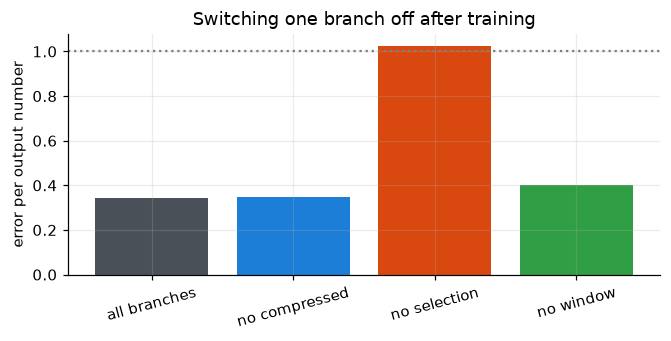

PASS  with all branches on, the ablation helper reproduces the model's own error   [0.346 vs 0.346]
PASS  removing selection hurts more than removing the compressed branch
PASS  removing the window hurts (the local term needs it)


In [12]:
@torch.no_grad()
def branch_ablation(model, n=64, seed=999, T=128, n_q=16):
    """Error (per output number) against the full target, with a branch's contribution zeroed at inference."""
    model.eval(); gen = torch.Generator().manual_seed(seed); x, y, far, local = make_retrieval_batch(n, T=T, gen=gen)
    h = model.inp(x); _, aux = model.layer(h, return_aux=True); L = model.layer
    res = {}
    for name, mask in {"all branches": (1, 1, 1), "no compressed": (0, 1, 1), "no selection": (1, 0, 1), "no window": (1, 1, 0)}.items():
        o = sum(m * aux["gate"][..., c:c + 1] * aux["o"][c] for c, m in enumerate(mask))
        B_, T_ = x.shape[:2]; yv = L.out(o.permute(0, 3, 1, 2, 4).reshape(B_, T_, -1))
        pred = model.out((h + yv)[:, -n_q:])
        res[name] = F.mse_loss(pred, y).item()
    model.train(); return res

abl = branch_ablation(nsa_m)
for k, v in abl.items(): print(f"{k:16s} error {v:.3f}")
gate_mean = nsa_m.layer.eval()(nsa_m.inp(make_retrieval_batch(32, gen=torch.Generator().manual_seed(5))[0]), return_aux=True)[1]["gate"][..., -16:, :].mean(dim=(0, 1, 2, 3))
print("mean gate at the scored positions  (compressed, selected, window):", gate_mean.detach().numpy().round(2))
fig, ax = plt.subplots(figsize=(6.2, 3.2)); ax.bar(list(abl), list(abl.values()), color=[FULL_C, CMP_C, SLC_C, WIN_C]); ax.axhline(1.0, color="gray", ls=":"); ax.set_ylabel("error per output number"); ax.set_title("Switching one branch off after training"); plt.xticks(rotation=15); plt.tight_layout(); plt.show()
check("with all branches on, the ablation helper reproduces the model's own error", abs(abl["all branches"] - mse_nsa) < 0.02, f"{abl['all branches']:.3f} vs {mse_nsa:.3f}")
check("removing selection hurts more than removing the compressed branch", abl["no selection"] > abl["no compressed"])
check("removing the window hurts (the local term needs it)", abl["no window"] > abl["all branches"] + 0.05)

**Reading it.** In our run, switching selection off sent the error to about 1.0 (retrieval gone), switching the compressed branch off changed almost nothing, and switching the window off cost a modest amount. We report them as they came out. The design intent (selection for the long-range lookup, window for the local term, compression as the cheap overview) is a hypothesis about division of labour, and this table is one seed of evidence for or against it at toy scale; it is not proof about the 27B model. One caution: because the gates are shared across heads' outputs and the layer has a single group, the division of labour may be cleaner or messier than it would be with 64 heads.

## Closing thoughts

The layer is small: three attention calls and a gate. The engineering is in making each call cheap (parts 1-3, 5) and the selection learnable (part 2). On our toy it learns the task but more slowly than full attention, which is the honest cost to put next to the paper's headline of matching full attention at scale. Part 6 asks the question this notebook sets up: does it matter that NSA was trained sparse, rather than sparsified afterwards?

**Claims that lack a number or baseline, for you to decide on:** (1) the toy's sparsity is modest (about four fifths of tokens), so nothing here supports a compute-saving claim; (2) one seed per model; (3) the branch-ablation reading assumes the zeroing leaves the rest of the model in a distribution it can handle, which we did not test; (4) the paper's 27B results in Figure 4 are quoted, not reproduced.

In [13]:
print(f"{sum(ok for _, ok in CHECKS)}/{len(CHECKS)} checks passed")
for n, ok in CHECKS:
    if not ok: print("FAILED:", n)
assert all(ok for _, ok in CHECKS), "some checks failed"

12/12 checks passed
